# 04 — MLP tự viết và đối chiếu scikit-learn

Khảo sát learning rate và kiến trúc, chọn cấu hình bằng validation, đánh giá train/validation/test. Feedforward và backpropagation nằm trong `src/models/mlp.py` (NumPy, ReLU → Softmax); notebook chỉ tổ chức thực nghiệm. Lý thuyết và pseudocode trình bày trong report.

Chạy từ thư mục gốc đồ án hoặc `notebooks/`. Hình PNG 300 dpi, bảng CSV và mô hình được lưu tại `results/mlp/`.


## 1. Import và chia dữ liệu

Dùng cùng split 50.000 train / 10.000 validation / 10.000 test, seed 42. Pixel đã chia 255 và làm phẳng; giữ nhãn nguyên. Dùng float64 ở cả hai cài đặt để hạn chế khác biệt về dtype.


In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from joblib import dump
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier as SklearnMLPClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
from src.models.mlp import MLPClassifier

SEED, EPOCHS, BATCH_SIZE = 42, 20, 256
L2 = 0.0  # Tắt ở cả hai bên để đối chiếu mà không khác quy ước chuẩn hóa L2.
OUTPUT = ROOT / 'results' / 'mlp'
OUTPUT.mkdir(parents=True, exist_ok=True)
X_all, y_all, X_test, y_test = load_prepared_mnist()
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=10000, stratify=y_all, random_state=SEED)
X_train, X_val, X_test = [X.astype(np.float64) for X in (X_train, X_val, X_test)]
del X_all
print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)


Train: (50000, 784) (50000,)
Validation: (10000, 784) (10000,)
Test: (10000, 784) (10000,)


## 2. Hàm hỗ trợ

Chỉ giữ hai hàm dùng lại: tính độ đo và dự đoán theo batch để giới hạn RAM. Không tắt cảnh báo hội tụ.


In [2]:
def metrics(y, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y, pred, labels=np.arange(10), average='macro', zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision_macro=precision, recall_macro=recall, f1_macro=f1)

def predict_batches(model, X):
    return np.concatenate([model.predict(X[i:i+1024]) for i in range(0, len(X), 1024)])


## 3. Huấn luyện các cấu hình khảo sát

Baseline: hai lớp ẩn `(256, 128)`, learning rate `0.08`. Thay riêng learning rate hoặc kiến trúc, giữ 20 epoch, batch 256, ReLU và L2=0. Mỗi cấu hình chỉ fit một lần; tái sử dụng baseline cho cả hai khảo sát.

Không khảo sát mọi tổ hợp. Tắt L2 là lựa chọn của thí nghiệm này, không phải kết luận regularization không có ích. Không dùng test trong bước chọn cấu hình.


In [3]:
configs = [
    ('baseline', (256, 128), 0.08),
    ('learning_rate', (256, 128), 0.01),
    ('learning_rate', (256, 128), 0.10),
    ('architecture', (128,), 0.08),
    ('architecture', (256,), 0.08),
    ('architecture', (256, 128, 64), 0.08),
]
models, rows = {}, []
for model_id, (group, hidden, lr) in enumerate(configs):
    print(f'Training hidden={hidden}, lr={lr}', flush=True)
    model = MLPClassifier(hidden_units=hidden, learning_rate=lr, epochs=EPOCHS, batch_size=BATCH_SIZE, l2=L2, seed=SEED)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - start
    pred = predict_batches(model, X_val)
    models[model_id] = model
    n_params = sum(W.size for W in model.weights_) + sum(b.size for b in model.biases_)
    rows.append(dict(model_id=model_id, group=group, hidden_units=str(hidden), learning_rate=lr,
        **metrics(y_val, pred), train_loss=model.history_[-1], n_parameters=n_params, fit_seconds=fit_s))
survey = pd.DataFrame(rows)
display(survey.round(5))


,model_id,group,hidden_units,learning_rate,accuracy,precision_macro,recall_macro,f1_macro,train_loss,n_parameters,fit_seconds
0,0,baseline,"(256, 128)",0.08,0.9706,0.97044,0.97047,0.97042,0.04696,235146,28.14943
1,1,learning_rate,"(256, 128)",0.01,0.9328,0.93276,0.93233,0.93242,0.22084,235146,28.92328
2,2,learning_rate,"(256, 128)",0.10,0.9724,0.97225,0.97236,0.97227,0.03575,235146,26.70782
3,3,architecture,"(128,)",0.08,0.9594,0.95915,0.95925,0.95910,0.11176,101770,14.68395
4,4,architecture,"(256,)",0.08,0.9627,0.96270,0.96242,0.96251,0.10419,203530,23.58052
5,5,architecture,"(256, 128, 64)",0.08,0.9756,0.97551,0.97544,0.97545,0.02369,242762,29.08440


Training hidden=(256, 128), lr=0.08
Training hidden=(256, 128), lr=0.01
Training hidden=(256, 128), lr=0.1
Training hidden=(128,), lr=0.08
Training hidden=(256,), lr=0.08
Training hidden=(256, 128, 64), lr=0.08


## 4. Ảnh hưởng của learning rate và kiến trúc

Mỗi biểu đồ so sánh các cấu hình cùng ngân sách 20 epoch. Kiến trúc được so sánh tại learning rate baseline; không khẳng định kiến trúc nào tốt nhất với mọi learning rate.


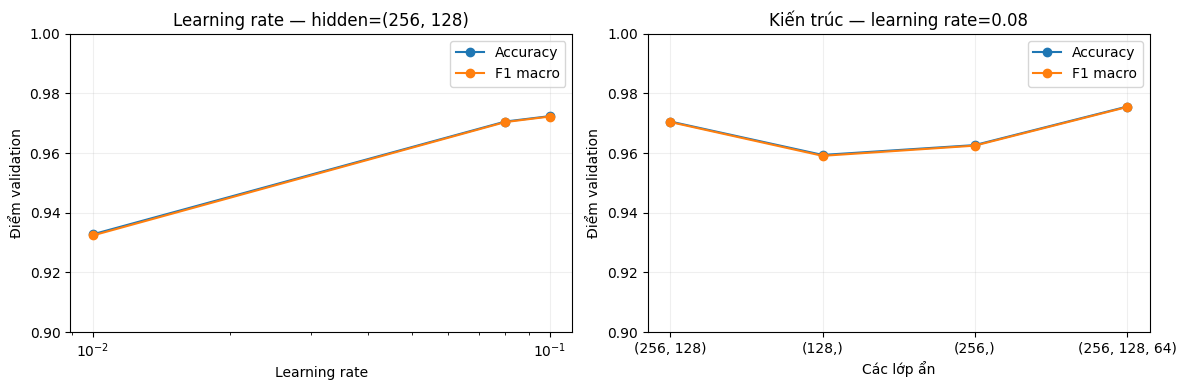

LR có F1 validation cao nhất trong khảo sát LR: 0.1
Kiến trúc có F1 validation cao nhất trong khảo sát kiến trúc: (256, 128, 64)


In [4]:
lr_results = survey[survey.group.isin(['baseline', 'learning_rate'])].sort_values('learning_rate')
arch_results = survey[survey.group.isin(['baseline', 'architecture'])].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, label in [('accuracy', 'Accuracy'), ('f1_macro', 'F1 macro')]:
    axes[0].semilogx(lr_results.learning_rate, lr_results[metric], marker='o', label=label)
    axes[1].plot(arch_results.hidden_units, arch_results[metric], marker='o', label=label)
axes[0].set(xlabel='Learning rate', title='Learning rate — hidden=(256, 128)')
axes[1].set(xlabel='Các lớp ẩn', title='Kiến trúc — learning rate=0.08')
for ax in axes:
    ax.set(ylabel='Điểm validation', ylim=(0.9, 1.0)); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUTPUT / 'hyperparameters.png', dpi=300)
plt.show()
print('LR có F1 validation cao nhất trong khảo sát LR:', lr_results.sort_values(['f1_macro', 'accuracy'], ascending=False).iloc[0].learning_rate)
print('Kiến trúc có F1 validation cao nhất trong khảo sát kiến trúc:', arch_results.sort_values(['f1_macro', 'accuracy'], ascending=False).iloc[0].hidden_units)


**Nhận xét lần chạy đính kèm:** trong khảo sát learning rate trên mạng (256, 128), giá trị 0,1 cho F1 validation cao nhất; trong khảo sát kiến trúc tại lr=0,08, mạng (256, 128, 64) cho F1 cao nhất. Chưa thử kết hợp kiến trúc này với lr=0,1; không khẳng định đã tìm cấu hình tối ưu toàn cục.


## 5. Chọn cấu hình và theo dõi loss

Chọn F1 macro validation cao nhất, accuracy phá hòa; nếu vẫn hòa ưu tiên ít tham số rồi `model_id` nhỏ hơn. Tái sử dụng mô hình đã fit, không huấn luyện lại và không dùng test để chọn. Đường loss là giá trị train cuối mỗi epoch; với L2=0 đây là cross-entropy. Không có early stopping hoặc chọn checkpoint trong cài đặt hiện tại.


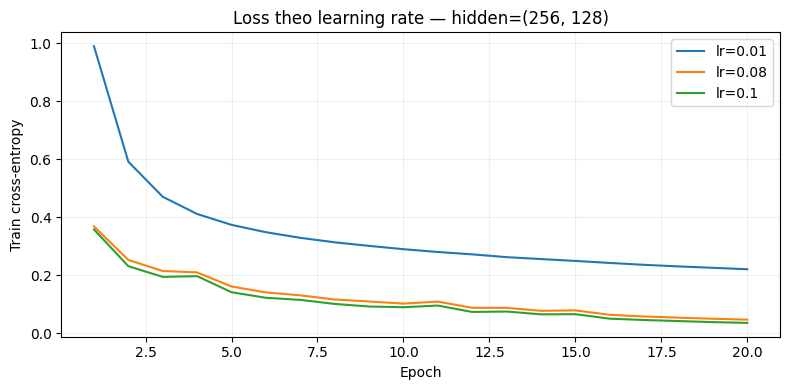

Cấu hình được chọn: (256, 128, 64) lr= 0.08
Validation accuracy=97.56%; F1 macro=0.9754


In [5]:
ranked = survey.sort_values(['f1_macro', 'accuracy', 'n_parameters', 'model_id'], ascending=[False, False, True, True])
best = ranked.iloc[0]
manual = models[int(best.model_id)]
best_hidden, best_lr = tuple(manual.hidden_units), float(manual.learning_rate)
print('Cấu hình được chọn:', best_hidden, 'lr=', best_lr)
print(f'Validation accuracy={best.accuracy:.2%}; F1 macro={best.f1_macro:.4f}')
fig, ax = plt.subplots(figsize=(8, 4))
for row in lr_results.itertuples():
    model = models[row.model_id]
    ax.plot(np.arange(1, EPOCHS+1), model.history_, label=f'lr={row.learning_rate:g}')
ax.set(xlabel='Epoch', ylabel='Train cross-entropy', title='Loss theo learning rate — hidden=(256, 128)')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(OUTPUT / 'learning_rate_loss.png', dpi=300)
plt.show()


## 6. Đối chiếu với MLP của sklearn

Dùng cùng kiến trúc đã chọn, ReLU, SGD không momentum, learning rate cố định, batch và 20 epoch, L2=0. Khởi tạo và thứ tự shuffle khác nhau giữa hai cài đặt nên không yêu cầu trọng số hoặc accuracy trùng nhau. So sánh này là đối chiếu hành vi, không phải phép kiểm chứng gradient tuyệt đối.

Sklearn có thể cảnh báo hết `max_iter` trước khi đạt tiêu chí hội tụ; giữ nguyên cảnh báo. `n_iter_` cho biết số epoch thực tế. Không so sánh trực tiếp hai loss nội bộ vì cách tổng hợp theo epoch có thể khác nhau.


In [6]:
reference = SklearnMLPClassifier(hidden_layer_sizes=best_hidden, activation='relu', solver='sgd',
    alpha=0.0, batch_size=BATCH_SIZE, learning_rate='constant', learning_rate_init=best_lr,
    max_iter=EPOCHS, momentum=0.0, nesterovs_momentum=False, tol=0.0,
    n_iter_no_change=EPOCHS+1, random_state=SEED)
start = time.perf_counter()
reference.fit(X_train, y_train)
reference_fit_s = time.perf_counter() - start
print('Số epoch sklearn:', reference.n_iter_)
print('Số tham số tự viết:', int(best.n_parameters))
print('Số tham số sklearn:', sum(W.size for W in reference.coefs_) + sum(b.size for b in reference.intercepts_))


Số epoch sklearn: 20
Số tham số tự viết: 242762
Số tham số sklearn: 242762


## 7. Đánh giá cấu hình cuối trên ba tập

Cả hai mô hình fit trên 50.000 train. Train là in-sample, validation đã dùng để chọn cấu hình, test là đánh giá cuối. Đo riêng fit và predict; mỗi thao tác đo một lần nên thời gian phụ thuộc môi trường. `fit_seconds` lặp lại ở ba split là cùng một lần fit, không cộng ba lần.


,model,split,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,MLP tự viết,Train,0.99494,0.99497,0.99490,0.99493,29.08440,0.42010
1,MLP tự viết,Validation,0.97560,0.97551,0.97544,0.97545,29.08440,0.10589
2,MLP tự viết,Test,0.97630,0.97633,0.97596,0.97612,29.08440,0.10513
3,MLP sklearn,Train,0.99052,0.99039,0.99058,0.99043,25.95409,0.45217
4,MLP sklearn,Validation,0.97010,0.96997,0.97005,0.96981,25.95409,0.07404
5,MLP sklearn,Test,0.97070,0.97042,0.97078,0.97046,25.95409,0.09277


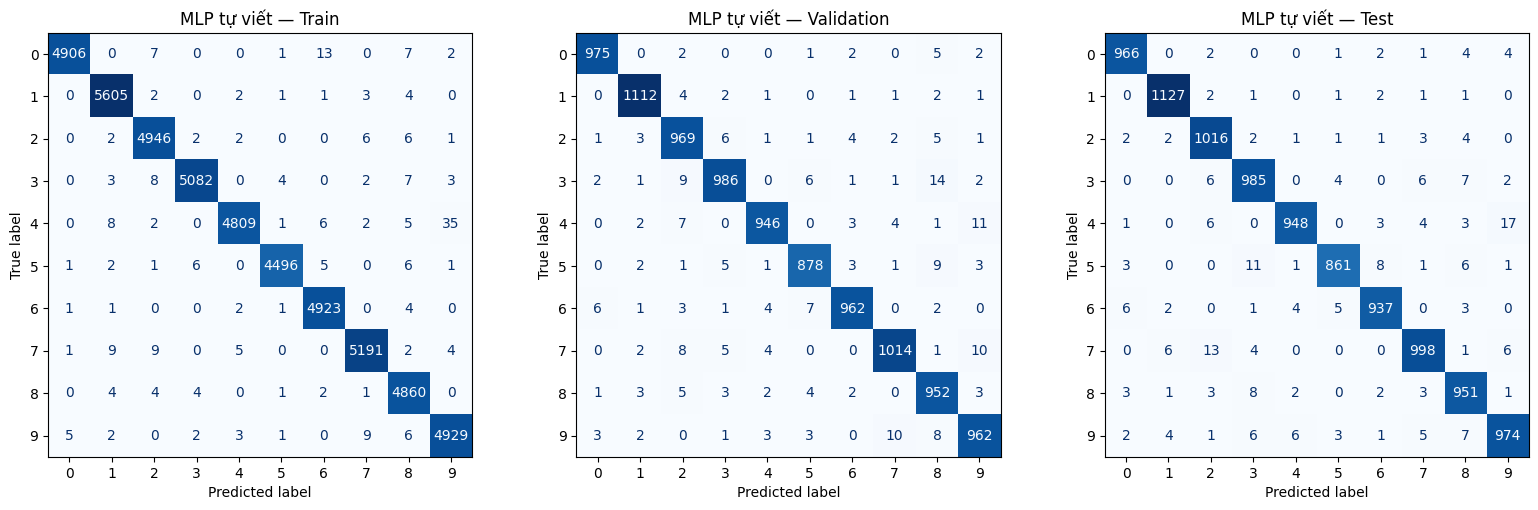

,model,split,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
2,MLP tự viết,Test,0.9763,0.97633,0.97596,0.97612,29.08440,0.10513
5,MLP sklearn,Test,0.9707,0.97042,0.97078,0.97046,25.95409,0.09277


Kết quả test:


In [7]:
datasets = {'Train': (X_train, y_train), 'Validation': (X_val, y_val), 'Test': (X_test, y_test)}
final_models = {'MLP tự viết': manual, 'MLP sklearn': reference}
rows, predictions = [], {}
for name, model in final_models.items():
    for split, (X, y) in datasets.items():
        start = time.perf_counter()
        pred = predict_batches(model, X)
        predict_s = time.perf_counter() - start
        predictions[name, split] = pred
        rows.append(dict(model=name, split=split, **metrics(y, pred),
            fit_seconds=float(best.fit_seconds) if name == 'MLP tự viết' else reference_fit_s, predict_seconds=predict_s))
results = pd.DataFrame(rows)
display(results.round(5))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (split, (_, y)) in zip(axes, datasets.items()):
    ConfusionMatrixDisplay.from_predictions(y, predictions['MLP tự viết', split], labels=np.arange(10),
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'MLP tự viết — {split}')
fig.tight_layout(); fig.savefig(OUTPUT / 'confusion_matrices.png', dpi=300)
plt.show()
print('Kết quả test:')
display(results[results.split == 'Test'].round(5))


**Nhận xét lần chạy đính kèm:** MLP tự viết đạt accuracy train/validation/test lần lượt 99.49% / 97.56% / 97.63%. Sklearn cảnh báo chưa hội tụ khi hết 20 epoch; bảng này so sánh cùng ngân sách epoch, không phải hiệu năng khi cả hai đã hội tụ. Không khẳng định cài đặt đúng chỉ vì accuracy gần nhau.


## 8. Phân tích lỗi và lưu kết quả

Chỉ hiển thị bảng theo lớp của mô hình tự viết để tránh lặp. Xuất confusion matrix cả hai mô hình trên ba tập, CSV, loss, cấu hình và file joblib cho suy luận; chỉ nạp joblib do chính bạn tạo. Chạy lại ghi đè các file cùng tên.


In [8]:
test_pred = predictions['MLP tự viết', 'Test']
report = pd.DataFrame(classification_report(y_test, test_pred, output_dict=True, zero_division=0)).T
display(report.loc[[str(k) for k in range(10)]].round(4))
print('Lớp có recall thấp nhất:', report.loc[[str(k) for k in range(10)], 'recall'].idxmin())
for name, table in {'metrics': results, 'survey': survey, 'learning_rate': lr_results, 'architecture': arch_results,
                    'history': pd.DataFrame({'epoch': np.arange(1, EPOCHS+1), 'train_loss': manual.history_})}.items():
    table.to_csv(OUTPUT / f'{name}.csv', index=False)
results.query("model == 'MLP tự viết' and split == 'Test'").to_csv(OUTPUT / 'comparison.csv', index=False)
report.to_csv(OUTPUT / 'classification_report_test.csv')
for name, model in final_models.items():
    prefix = 'manual' if name == 'MLP tự viết' else 'sklearn'
    for split, (_, y) in datasets.items():
        cm = confusion_matrix(y, predictions[name, split], labels=np.arange(10))
        pd.DataFrame(cm, index=np.arange(10), columns=np.arange(10)).to_csv(OUTPUT / f'{prefix}_confusion_{split.lower()}.csv', index_label='true_digit')
config = dict(seed=SEED, hidden_units=list(best_hidden), learning_rate=best_lr, epochs=EPOCHS, l2=L2,
    batch_size=BATCH_SIZE, dtype='float64', n_parameters=int(best.n_parameters), train_samples=len(y_train),
    validation_samples=len(y_val), test_samples=len(y_test), selection='F1 macro, accuracy, it tham so, model_id',
    search_fit_seconds=float(survey.fit_seconds.sum()), sklearn_version=sklearn.__version__)
(OUTPUT / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
dump(manual, OUTPUT / 'manual_model.joblib')
print('Đã lưu:', OUTPUT)


,precision,recall,f1-score,support
0,0.9827,0.9857,0.9842,980.0
1,0.9869,0.9930,0.9899,1135.0
2,0.9685,0.9845,0.9765,1032.0
3,0.9676,0.9752,0.9714,1010.0
4,0.9854,0.9654,0.9753,982.0
5,0.9829,0.9652,0.9740,892.0
6,0.9801,0.9781,0.9791,958.0
7,0.9765,0.9708,0.9737,1028.0
8,0.9635,0.9764,0.9699,974.0
9,0.9692,0.9653,0.9672,1009.0


Lớp có recall thấp nhất: 5
Đã lưu: /workspace/scratch/31fe42f8b30e/review/mn/results/mlp


**Kết luận:** MLP học đặc trưng phi tuyến qua các lớp ẩn, đổi lại có nhiều tham số và cần huấn luyện lặp. Dùng số liệu trong `comparison.csv` để so sánh với Gaussian NB, Softmax và Ensemble trên cùng split; thảo luận chi tiết trong report.
